# Bank Marketing Campaign Effectiveness & Customer Conversion Analytics
### An End-to-End Data Analytics Project for Improving Marketing Campaign Conversion

**Business question:** Which customer and campaign characteristics are associated with
successful term-deposit subscriptions, and how can the bank improve marketing campaign
conversion?

**Dataset:** UCI Machine Learning Repository — *Bank Marketing* (bank-additional-full.csv),
41,188 records, 20 input attributes + target `y`.
Source: https://archive.ics.uci.edu/dataset/222/bank+marketing

**Pipeline followed in this notebook:**

```
DATA → DATA UNDERSTANDING → DATA CLEANING → BUSINESS QUESTIONS → EDA →
OBSERVATIONS → INSIGHTS → RISK/OPPORTUNITY/ACTION → PREDICTIVE ANALYSIS →
BUSINESS RECOMMENDATIONS
```


## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
%matplotlib inline


## 1. Data

The raw file is the original UCI CSV, saved unmodified at
`data/raw/bank_marketing.csv`. It is semicolon-separated.


In [2]:
df = pd.read_csv("../data/raw/bank_marketing.csv", sep=";")
print("Shape:", df.shape)
df.head()


Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Data Understanding

**Customer attributes:** age, job, marital, education, default, housing, loan

**Campaign/contact attributes:** contact, month, day_of_week, duration, campaign, pdays, previous, poutcome

**Economic/context attributes:** emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed

**Target:** `y` — has the client subscribed to a term deposit? (`yes` / `no`)

> **Important note on `duration`:** the UCI documentation states this attribute is only
> known *after* a call is completed (a call that ends at 0 seconds means `y = "no"`
> almost by definition). It is very useful for descriptive analysis but must be **excluded
> from the predictive model**, otherwise the model would be cheating by "knowing the
> future" — this is a classic case of *data leakage*. We use it for EDA insights only.


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [4]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df["y"].value_counts()


y
no     36548
yes     4640
Name: count, dtype: int64

In [6]:
print("Class balance:")
print(df["y"].value_counts(normalize=True).round(4) * 100, "%")


Class balance:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64 %


## 3. Data Cleaning

Steps performed:
1. Check and remove exact duplicate rows.
2. Check for missing values (there are none as `NaN`, but several categorical
   columns use the string `"unknown"` as a *documented* placeholder for missing
   information — this is kept as its own category rather than imputed, since
   dropping ~21% of `default` rows, for example, would discard real information).
3. Flag the `pdays` sentinel value `999` (meaning *"never previously contacted"*)
   with a readable `was_previously_contacted` column.
4. Convert the target `y` into a binary numeric column `y_binary` for analysis.


In [7]:
print("Duplicate rows:", df.duplicated().sum())
df_clean = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df_clean.shape)


Duplicate rows: 12


Shape after removing duplicates: (41176, 21)


In [8]:
# 'unknown' counts per categorical column
cat_cols = df_clean.select_dtypes(include="object").columns
unknown_counts = {c: (df_clean[c] == "unknown").sum() for c in cat_cols if (df_clean[c] == "unknown").sum() > 0}
pd.Series(unknown_counts, name="unknown_count").sort_values(ascending=False)


/tmp/ipykernel_211/2803976067.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_clean.select_dtypes(include="object").columns


default      8596
education    1730
housing       990
loan          990
job           330
marital        80
Name: unknown_count, dtype: int64

In [9]:
# Flag whether the customer was contacted in a previous campaign (pdays == 999 -> never contacted)
df_clean["was_previously_contacted"] = np.where(df_clean["pdays"] == 999, "no", "yes")

# Binary target
df_clean["y_binary"] = (df_clean["y"] == "yes").astype(int)

df_clean.to_csv("../data/processed/bank_marketing_clean.csv", index=False)
df_clean.shape


(41176, 23)

## 4. Business Questions

1. What is the overall campaign conversion (subscription) rate?
2. Which **customer segments** (age, job, education, marital status) convert best?
3. Which **contact channel and timing** choices are associated with higher conversion?
4. Does **repeated contact** within a campaign help or hurt conversion?
5. Does a customer's **history with previous campaigns** predict future conversion?
6. How do **macroeconomic conditions** relate to campaign success?
7. Can we **predict**, before calling a customer, whether they are likely to subscribe?


## 5. Exploratory Data Analysis

### 5.1 Overall conversion rate


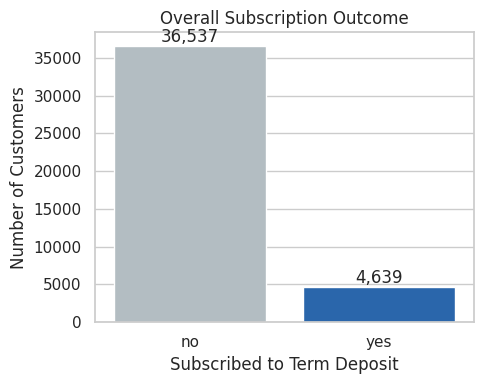

Overall conversion rate: 11.27%


In [10]:
plt.figure(figsize=(5,4))
ax = sns.countplot(x="y", data=df_clean, order=["no","yes"], hue="y",
                    palette=["#B0BEC5","#1565C0"], legend=False)
ax.set_title("Overall Subscription Outcome")
ax.set_xlabel("Subscribed to Term Deposit")
ax.set_ylabel("Number of Customers")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x()+p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig("../outputs/figures/01_target_distribution.png", dpi=150)
plt.show()

rate = df_clean["y_binary"].mean()*100
print(f"Overall conversion rate: {rate:.2f}%")


### 5.2 Subscription rate by occupation

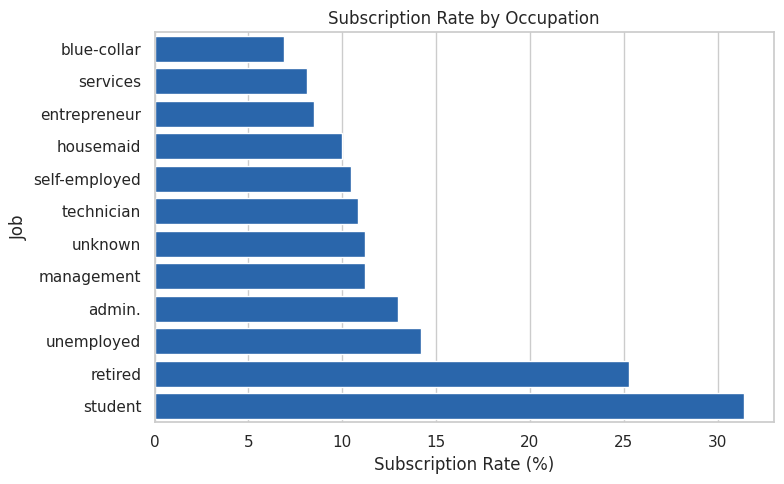

,mean,count
job,,
student,31.43,875
retired,25.26,1718
unemployed,14.20,1014
admin.,12.97,10419
management,11.22,2924
unknown,11.21,330
technician,10.83,6739
self-employed,10.49,1421
housemaid,10.00,1060


In [11]:
job_rate = df_clean.groupby("job")["y_binary"].agg(["mean","count"]).sort_values("mean")
job_rate["mean"] = (job_rate["mean"]*100).round(2)

plt.figure(figsize=(8,5))
ax = sns.barplot(x=job_rate["mean"], y=job_rate.index, color="#1565C0")
ax.set_title("Subscription Rate by Occupation")
ax.set_xlabel("Subscription Rate (%)"); ax.set_ylabel("Job")
plt.tight_layout()
plt.savefig("../outputs/figures/02_rate_by_job.png", dpi=150)
plt.show()
job_rate.sort_values("mean", ascending=False)


### 5.3 Subscription rate by education

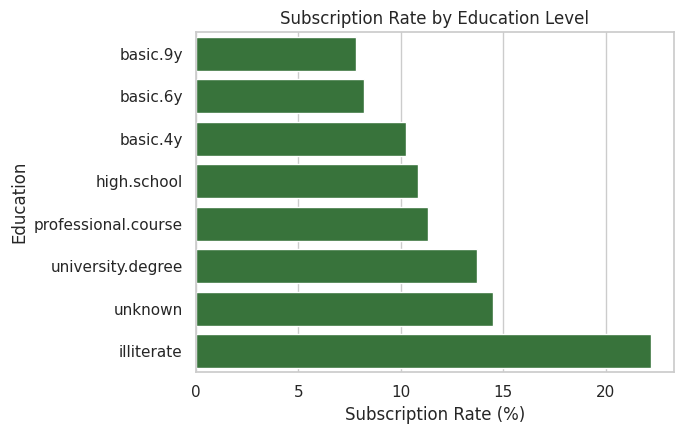

,mean,count
education,,
illiterate,22.22,18
unknown,14.51,1730
university.degree,13.72,12164
professional.course,11.35,5240
high.school,10.84,9512
basic.4y,10.25,4176
basic.6y,8.21,2291
basic.9y,7.82,6045


In [12]:
edu_rate = df_clean.groupby("education")["y_binary"].agg(["mean","count"]).sort_values("mean")
edu_rate["mean"] = (edu_rate["mean"]*100).round(2)

plt.figure(figsize=(7,4.5))
ax = sns.barplot(x=edu_rate["mean"], y=edu_rate.index, color="#2E7D32")
ax.set_title("Subscription Rate by Education Level")
ax.set_xlabel("Subscription Rate (%)"); ax.set_ylabel("Education")
plt.tight_layout()
plt.savefig("../outputs/figures/03_rate_by_education.png", dpi=150)
plt.show()
edu_rate.sort_values("mean", ascending=False)


### 5.4 Subscription rate by age group

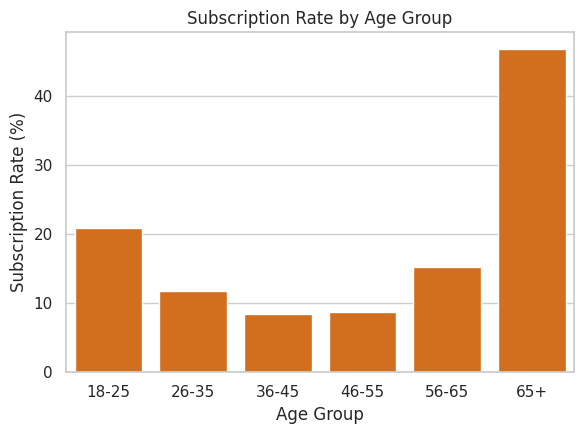

,mean,count
age_group,,
18-25,20.90,1660
26-35,11.72,14844
36-45,8.51,12839
46-55,8.69,8247
56-65,15.22,2963
65+,46.93,618


In [13]:
bins = [17,25,35,45,55,65,100]
labels = ["18-25","26-35","36-45","46-55","56-65","65+"]
df_clean["age_group"] = pd.cut(df_clean["age"], bins=bins, labels=labels)

age_rate = df_clean.groupby("age_group", observed=True)["y_binary"].agg(["mean","count"])
age_rate["mean"] = (age_rate["mean"]*100).round(2)

plt.figure(figsize=(6,4.5))
ax = sns.barplot(x=age_rate.index, y=age_rate["mean"], color="#EF6C00")
ax.set_title("Subscription Rate by Age Group")
ax.set_xlabel("Age Group"); ax.set_ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.savefig("../outputs/figures/04_rate_by_age_group.png", dpi=150)
plt.show()
age_rate


### 5.5 Subscription rate by contact channel

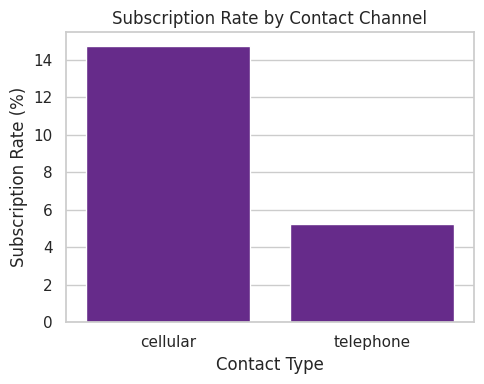

,mean,count
contact,,
cellular,14.74,26135
telephone,5.23,15041


In [14]:
contact_rate = df_clean.groupby("contact")["y_binary"].agg(["mean","count"])
contact_rate["mean"] = (contact_rate["mean"]*100).round(2)

plt.figure(figsize=(5,4))
ax = sns.barplot(x=contact_rate.index, y=contact_rate["mean"], color="#6A1B9A")
ax.set_title("Subscription Rate by Contact Channel")
ax.set_xlabel("Contact Type"); ax.set_ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.savefig("../outputs/figures/05_rate_by_contact.png", dpi=150)
plt.show()
contact_rate


### 5.6 Subscription rate by month of last contact

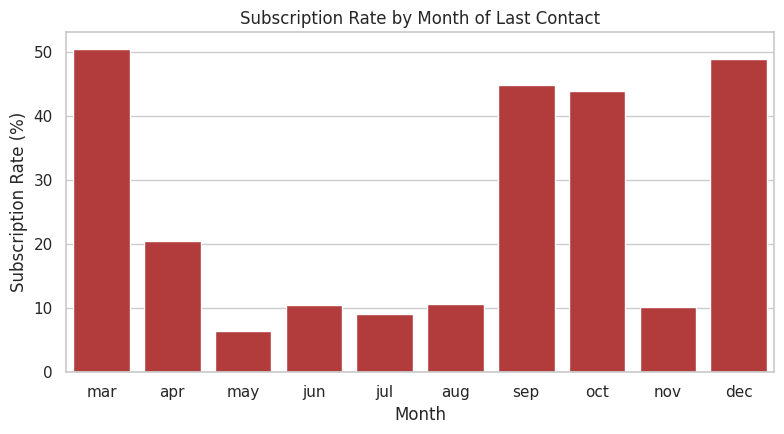

,mean,count
month,,
mar,50.55,546
apr,20.49,2631
may,6.44,13767
jun,10.51,5318
jul,9.04,7169
aug,10.61,6176
sep,44.91,570
oct,43.93,717
nov,10.15,4100


In [15]:
month_order = ["mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
month_rate = df_clean.groupby("month")["y_binary"].agg(["mean","count"])
month_rate["mean"] = (month_rate["mean"]*100).round(2)
month_rate = month_rate.reindex([m for m in month_order if m in month_rate.index])

plt.figure(figsize=(8,4.5))
ax = sns.barplot(x=month_rate.index, y=month_rate["mean"], color="#C62828")
ax.set_title("Subscription Rate by Month of Last Contact")
ax.set_xlabel("Month"); ax.set_ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.savefig("../outputs/figures/06_rate_by_month.png", dpi=150)
plt.show()
month_rate


### 5.7 Effect of previous campaign outcome

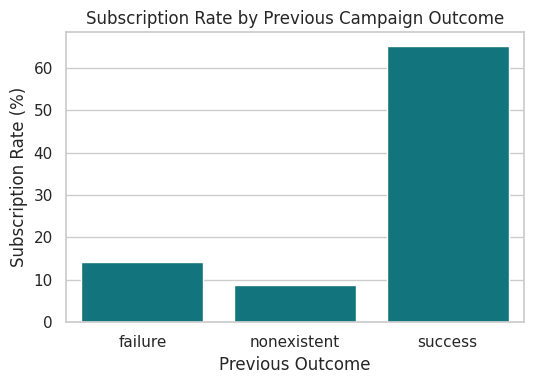

,mean,count
poutcome,,
success,65.11,1373
failure,14.23,4252
nonexistent,8.83,35551


In [16]:
poutcome_rate = df_clean.groupby("poutcome")["y_binary"].agg(["mean","count"])
poutcome_rate["mean"] = (poutcome_rate["mean"]*100).round(2)

plt.figure(figsize=(5.5,4))
ax = sns.barplot(x=poutcome_rate.index, y=poutcome_rate["mean"], color="#00838F")
ax.set_title("Subscription Rate by Previous Campaign Outcome")
ax.set_xlabel("Previous Outcome"); ax.set_ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.savefig("../outputs/figures/07_rate_by_poutcome.png", dpi=150)
plt.show()
poutcome_rate.sort_values("mean", ascending=False)


### 5.8 Number of contacts this campaign vs. outcome

Avg. campaign contacts (subscribed): 2.05
Avg. campaign contacts (not subscribed): 2.63


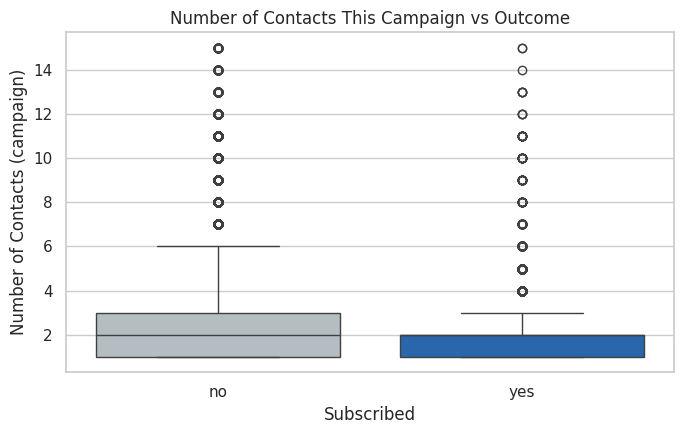

In [17]:
print("Avg. campaign contacts (subscribed):", round(df_clean[df_clean.y_binary==1]["campaign"].mean(),2))
print("Avg. campaign contacts (not subscribed):", round(df_clean[df_clean.y_binary==0]["campaign"].mean(),2))

plt.figure(figsize=(7,4.5))
sub = df_clean[df_clean["campaign"] <= 15]
ax = sns.boxplot(x="y", y="campaign", data=sub, order=["no","yes"], hue="y",
                  palette=["#B0BEC5","#1565C0"], legend=False)
ax.set_title("Number of Contacts This Campaign vs Outcome")
ax.set_xlabel("Subscribed"); ax.set_ylabel("Number of Contacts (campaign)")
plt.tight_layout()
plt.savefig("../outputs/figures/08_campaign_contacts_vs_outcome.png", dpi=150)
plt.show()


### 5.9 Correlation between numeric variables

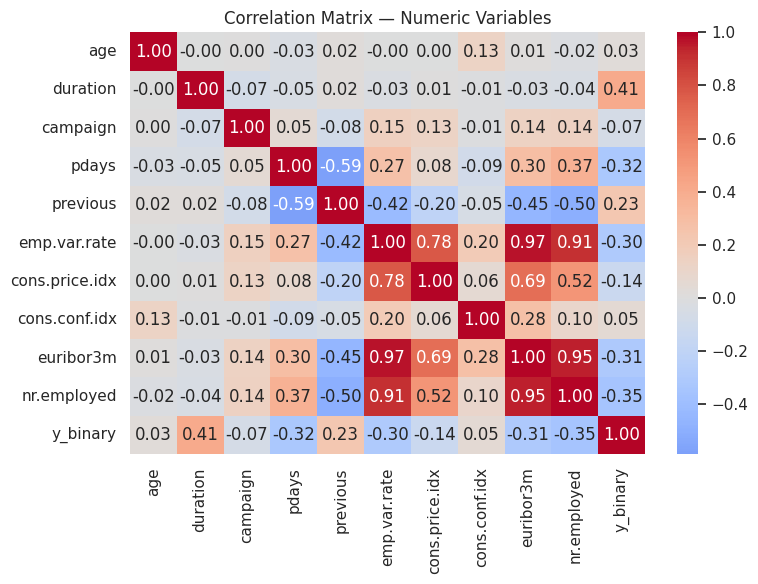

In [18]:
num_cols = ["age","duration","campaign","pdays","previous","emp.var.rate",
            "cons.price.idx","cons.conf.idx","euribor3m","nr.employed","y_binary"]
corr = df_clean[num_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix — Numeric Variables")
plt.tight_layout()
plt.savefig("../outputs/figures/09_correlation_heatmap.png", dpi=150)
plt.show()


## 6. Observations

- The dataset is **imbalanced**: only about **11.3%** of contacted customers subscribed.
- **Students (≈31%)** and **retirees (≈25%)** convert far above the ~11% average;
  **blue-collar (≈7%)** and **services (≈8%)** convert below it.
- Conversion is **U-shaped by age**: the youngest (18–25) and oldest (65+) age groups
  convert much better than the 26–55 "working middle" segment.
- **Cellular contact (≈14.7%)** converts almost 3× better than **telephone (≈5.2%)**.
- Conversion varies strongly by **month** — March, September, October and December
  show conversion rates above 40%, while May (the busiest calling month) converts at
  only ≈6.4%.
- Customers with a **successful previous campaign outcome** convert at **≈65%**,
  vastly higher than customers who were never previously contacted (≈9%).
- Customers who eventually said **yes were contacted fewer times on average**
  (≈2.1 contacts) than those who said **no** (≈2.6 contacts) — more repeated calling
  is associated with *lower*, not higher, conversion.
- Macroeconomic variables (`euribor3m`, `emp.var.rate`, `nr.employed`) are strongly
  correlated with each other and with the target — subscriptions rise when the
  economy is comparatively cooler (lower interest rates / lower employment
  variation), consistent with money moving toward term deposits in that environment.


## 7. Insights

1. **Segment targeting matters more than volume.** Students and retirees are a
   small share of calls but a disproportionately large share of conversions —
   the bank is likely under-targeting these segments relative to their potential.
2. **Channel choice is a lever, not a formality.** Cellular contact outperforms
   landline by a wide margin, likely because it reaches customers more personally
   and at more flexible times.
3. **Timing is a lever.** Campaigns launched outside the traditional heavy-calling
   months (spring/autumn vs. May) see materially higher success — this may reflect
   less "calling fatigue" among prospects or better-targeted smaller campaigns in
   those months.
4. **Diminishing returns to repeated contact.** Pushing past 2–3 contacts with the
   same customer in one campaign does not improve, and may hurt, conversion.
5. **Past behavior is the single strongest campaign-level signal.** A customer who
   said "yes" before is roughly **7× more likely** to say yes again than someone
   never previously contacted.
6. **Macroeconomic context shapes appetite for term deposits** independent of how
   well the campaign itself is run.


## 8. Risk, Opportunity, and Action

| Area | Risk | Opportunity | Action |
|---|---|---|---|
| Over-calling | Repeated contacts (`campaign` > 3) show falling returns and customer fatigue / annoyance risk | Free up agent time | Cap standard campaigns at **2–3 contacts** per customer |
| Channel mix | Telephone-only contact wastes agent time on a channel converting at <6% | Cellular contact converts ~3x better | Prioritize cellular contact wherever a valid mobile number exists |
| Segment mis-targeting | Broad, undifferentiated calling lists dilute effort on low-converting segments (blue-collar, services) | Students & retirees convert 2–3x the average | Build **segment-prioritized call lists**, without excluding other segments — just sequencing them by expected conversion |
| Seasonality | Heavy May-dominated calling wastes volume on the lowest-converting month | Spring/autumn windows convert far better | Shift a larger share of campaign volume toward Mar/Sep/Oct/Dec where feasible |
| Ignoring history | Treating every contact as "cold" ignores a very strong signal | Past successful customers convert at ~65% | Build a **warm re-engagement list** of previously successful customers ahead of new campaigns |


## 9. Predictive Analysis — Logistic Regression

Predictive analytics is appropriate here: the bank wants to **prioritize which
customers to call next**, which is a binary classification problem
(`y`: will subscribe / will not subscribe).

**Model choice:** Logistic Regression — simple, fast, and interpretable
(coefficients show direction/strength of each factor), which fits the "keep it
simple" requirement of this project.

**Leakage control:** `duration` is dropped from the feature set, since it is
only known after a call is completed and would not be available at the moment
the bank decides *whether* to call a customer.

**Class imbalance:** handled with `class_weight="balanced"` in place of more
complex resampling techniques, keeping the pipeline simple.


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                              roc_curve, accuracy_score, precision_score, recall_score, f1_score)

model_df = df_clean.drop(columns=["y", "duration", "age_group"])
y = model_df["y_binary"]
X = model_df.drop(columns=["y_binary"])

cat_cols = X.select_dtypes(include="object").columns.tolist()
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)
logreg.fit(X_train_scaled, y_train)

y_pred = logreg.predict(X_test_scaled)
y_proba = logreg.predict_proba(X_test_scaled)[:, 1]

print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])
print("Number of features (after one-hot encoding):", X_encoded.shape[1])


/tmp/ipykernel_211/2791488001.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns.tolist()


Train size: 32940  Test size: 8236
Number of features (after one-hot encoding): 53


In [20]:
print(classification_report(y_test, y_pred, target_names=["no","yes"]))
print("ROC AUC:", round(roc_auc_score(y_test, y_proba), 4))


              precision    recall  f1-score   support

          no       0.95      0.85      0.90      7308
         yes       0.36      0.65      0.46       928

    accuracy                           0.83      8236
   macro avg       0.65      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236

ROC AUC: 0.8002


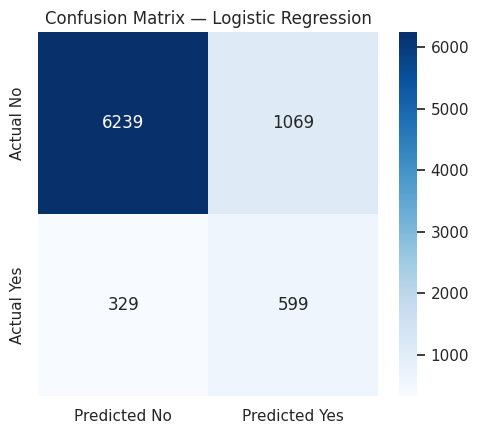

In [21]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted No","Predicted Yes"],
            yticklabels=["Actual No","Actual Yes"])
plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()
plt.savefig("../outputs/figures/10_confusion_matrix.png", dpi=150)
plt.show()


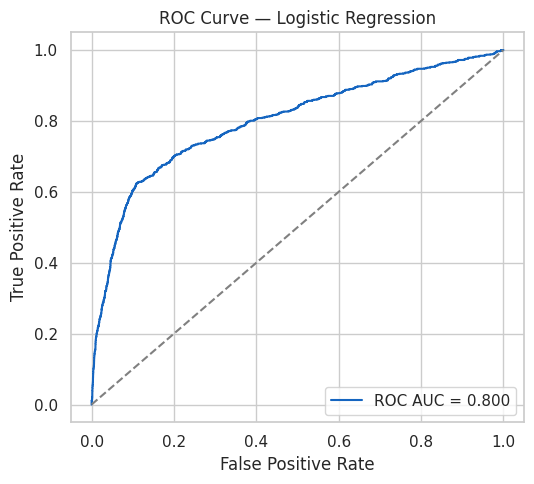

In [22]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(5.5,5))
plt.plot(fpr, tpr, color="#1565C0", label=f"ROC AUC = {auc:.3f}")
plt.plot([0,1],[0,1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Logistic Regression")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../outputs/figures/11_roc_curve.png", dpi=150)
plt.show()


### 9.1 Which features drive predictions?

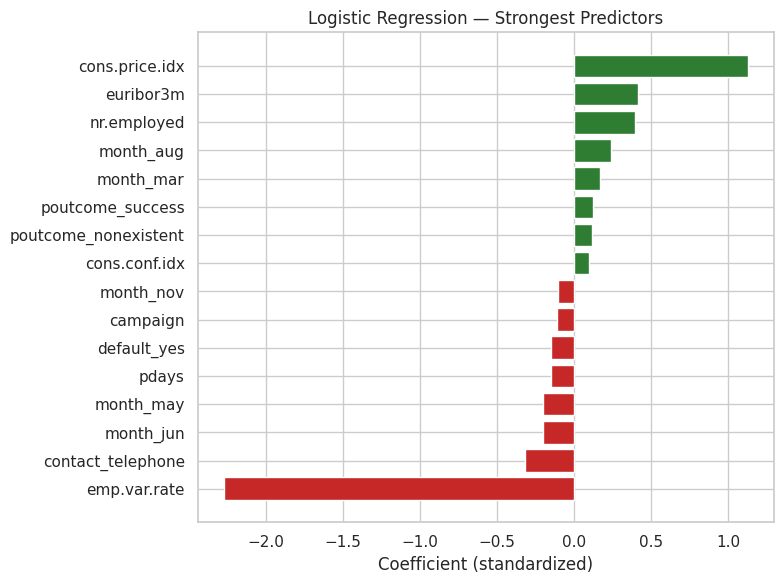

,feature,coefficient
5,cons.price.idx,1.129172
7,euribor3m,0.418424
8,nr.employed,0.395975
37,month_aug,0.239512
41,month_mar,0.172307
51,poutcome_success,0.122181
50,poutcome_nonexistent,0.116162
6,cons.conf.idx,0.098815
52,was_previously_contacted_yes,0.091791
21,marital_single,0.078441


In [23]:
coef_df = pd.DataFrame({
    "feature": X_encoded.columns,
    "coefficient": logreg.coef_[0]
}).sort_values("coefficient", ascending=False)

top_feats = pd.concat([coef_df.head(8), coef_df.tail(8)]).sort_values("coefficient")

plt.figure(figsize=(8,6))
colors = ["#C62828" if v < 0 else "#2E7D32" for v in top_feats["coefficient"]]
plt.barh(top_feats["feature"], top_feats["coefficient"], color=colors)
plt.title("Logistic Regression — Strongest Predictors")
plt.xlabel("Coefficient (standardized)")
plt.tight_layout()
plt.savefig("../outputs/figures/12_top_features.png", dpi=150)
plt.show()

coef_df.head(10)


**Model interpretation:**

- Economic context (`cons.price.idx`, `euribor3m`, `nr.employed`, `emp.var.rate`) and
  contact `month` dominate the top predictors, confirming the EDA: **when** a campaign
  runs matters as much as **who** is called.
- `poutcome_success` and `was_previously_contacted_yes` are strong positive predictors,
  confirming that past engagement is a powerful signal.
- `contact_telephone` and higher `campaign` counts are negative predictors, confirming
  the channel and over-calling findings from the EDA.
- Model quality (test set): **accuracy ≈ 83%**, **recall ≈ 65%**, **ROC AUC ≈ 0.80** —
  solid for a simple, fully interpretable baseline used to **rank and prioritize**
  customers to call, not as a black-box final decision-maker.


## 10. Business Recommendations

1. **Prioritize cellular contact** over telephone wherever possible — nearly 3x
   the conversion rate for the same calling effort.
2. **Re-engage previous successful customers first** in any new campaign — this
   single segment converts at ~65%, by far the highest of any group identified.
3. **Cap contact attempts at 2–3 per customer** per campaign; beyond that,
   diminishing (and likely negative) returns set in.
4. **Sequence call lists by expected conversion**, using the logistic regression
   model's predicted probability, so agents spend time on customers most likely
   to convert — informed by segment (student/retiree skew high), history
   (previous success), and channel (cellular).
5. **Concentrate campaign volume in higher-converting months** (March, September,
   October, December) where scheduling allows, rather than defaulting to
   traditionally busy months like May.
6. **Monitor macroeconomic indicators** (euribor, employment variation) as a
   leading signal for adjusting campaign scale and intensity — term deposits
   become more attractive to customers when these indicators are lower.


## 11. Limitations

- The dataset covers a single Portuguese bank's campaigns (2008–2010) — findings
  may not generalize directly to other markets or time periods.
- `duration` was deliberately excluded from the predictive model to avoid leakage,
  which means the model cannot use "how the call is going" — it is designed to be
  used **before** a call takes place, not during one.
- Class imbalance (~11% positive class) means precision is modest (~36%); the
  model is tuned to **maximize recall** (finding likely subscribers) rather than
  minimizing false positives, which fits a "who do we call next" use case.
- Logistic Regression assumes roughly linear/additive relationships; a more
  complex model (e.g., Random Forest) could capture interactions, but was judged
  unnecessary added complexity for this project's stated business questions.


## 12. Conclusion

This analysis shows that campaign conversion is driven less by generic "who to
call" demographics and more by **channel, timing, contact frequency, and prior
customer history** — all of which are within the bank's direct control. Combined
with a simple, interpretable logistic regression model to rank customers by
likelihood to subscribe, the bank has a practical, low-complexity path to
materially improving term-deposit campaign conversion without changing its core
calling process.
